In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
df=pd.read_csv('/content/child_depression (2).csv')
df

ModuleNotFoundError: No module named 'seaborn'

In [ ]:
df.dtypes

,0
gender,object
academic_pressure_1to5,float64
phq_depression_score_0to27,int64
housing_insecurity,int64
income_level,object
ace_neglect_count,int64
suicidal_ideation_past_12m,float64
respondent_id,int64
age_in_months,int64
favorite_color,object


In [ ]:
df.isna().sum()

,0
gender,0
academic_pressure_1to5,222
phq_depression_score_0to27,0
housing_insecurity,0
income_level,137
ace_neglect_count,0
suicidal_ideation_past_12m,456
respondent_id,0
age_in_months,0
favorite_color,0


In [ ]:
df.shape

(8000, 32)

In [ ]:
df.duplicated().sum()

np.int64(0)

In [ ]:
df=df.rename(columns={
    'depression_diagnosis':'is_depressed',
    'phq_depression_score_0to27':'phq_score',
    'academic_pressure_1to5':'academic_pressure',
    'social_support_1to5':'social_support',
    'parent_child_relationship_1to5':'parent_relationship',
    'food_insecurity_0to2':'food_insecurity',
    'housing_insecurity':'housing_insecure',
    'suicidal_ideation_past_12m':'suicidal_ideation_12m',
    'cyberbullied_past_12m':'cyberbullied_12m',
    'bullied_past_30days':'bullied_30d',
    'trusted_adult':'has_trusted_adult',
    'discrimination_experienced':'faced_discrimination',
    'ace_neglect_count':'ace_neglect',
    'ace_abuse_count':'ace_abuse',
    'ace_household_count':'ace_household'})

In [ ]:
df.columns

Index(['gender', 'academic_pressure', 'phq_score', 'housing_insecure',
       'income_level', 'ace_neglect', 'suicidal_ideation_12m', 'respondent_id',
       'age_in_months', 'favorite_color', 'ace_abuse', 'survey_version',
       'social_support', 'cyberbullied_12m', 'shoe_size', 'food_insecurity',
       'ace_total_score', 'has_trusted_adult', 'parent_relationship', 'age',
       'random_number', 'sleep_hours', 'faced_discrimination', 'survey_date',
       'sleep_minutes', 'mother_occupation', 'bullied_30d', 'interviewer_code',
       'health_risk_level', 'country', 'ace_household', 'is_depressed'],
      dtype='object')

In [ ]:
df.describe()

,academic_pressure,phq_score,housing_insecure,ace_neglect,suicidal_ideation_12m,respondent_id,age_in_months,ace_abuse,survey_version,social_support,...,has_trusted_adult,parent_relationship,age,random_number,sleep_hours,faced_discrimination,sleep_minutes,bullied_30d,ace_household,is_depressed
count,7778.000000,8000.000000,8000.000000,8000.000000,7544.000000,8000.000000,8000.000000,8000.000000,8000.0,8000.000000,...,8000.00000,7720.000000,8000.00000,8000.000000,7764.000000,8000.000000,7764.000000,8000.000000,8000.000000,8000.000000
mean,3.135510,9.821625,0.145750,0.713500,0.098754,7872.742125,175.757875,0.797250,1.0,2.909000,...,0.57925,3.041192,14.18375,492.585250,6.822012,0.185250,409.320711,0.459000,1.238375,0.720000
std,0.933646,5.105983,0.352877,0.687733,0.298351,3643.095809,24.518593,0.749642,0.0,0.939457,...,0.49371,1.031497,2.04805,288.391777,1.224353,0.388525,73.461175,0.498347,1.023686,0.449027
min,1.000000,0.000000,0.000000,0.000000,0.000000,2.000000,120.000000,0.000000,1.0,1.000000,...,0.00000,1.000000,10.00000,0.000000,3.000000,0.000000,180.000000,0.000000,0.000000,0.000000
25%,3.000000,7.000000,0.000000,0.000000,0.000000,5011.750000,158.000000,0.000000,1.0,2.000000,...,0.00000,2.000000,13.00000,236.000000,6.000000,0.000000,360.000000,0.000000,0.000000,0.000000
50%,3.000000,11.000000,0.000000,1.000000,0.000000,8839.500000,179.000000,1.000000,1.0,3.000000,...,1.00000,3.000000,14.00000,483.000000,6.800000,0.000000,408.000000,0.000000,1.000000,1.000000
75%,4.000000,13.000000,0.000000,1.000000,0.000000,10839.250000,196.000000,1.000000,1.0,4.000000,...,1.00000,4.000000,16.00000,744.000000,7.600000,0.000000,456.000000,1.000000,2.000000,1.000000
max,5.000000,26.000000,1.000000,2.000000,1.000000,12839.000000,215.000000,3.000000,1.0,5.000000,...,1.00000,5.000000,17.00000,999.000000,11.000000,1.000000,660.000000,1.000000,5.000000,1.000000


In [ ]:
missing=pd.DataFrame({
    'missing_count':df.isna().sum(),
    'missing_percent':(df.isna().mean()*100).round(1)})
missing=missing[missing.missing_count>0].sort_values('missing_count',ascending=False)
print(missing)


                       missing_count  missing_percent
mother_occupation               5247             65.6
suicidal_ideation_12m            456              5.7
parent_relationship              280              3.5
food_insecurity                  279              3.5
sleep_hours                      236              2.9
sleep_minutes                    236              2.9
academic_pressure                222              2.8
income_level                     137              1.7


In [ ]:
df=df.drop(columns=['phq_score','health_risk_level','respondent_id','random_number',
                    'favorite_color','shoe_size','survey_version','interviewer_code',
                    'survey_date','mother_occupation','sleep_minutes','age_in_months',
                    'ace_total_score'])

In [ ]:
df.shape

(8000, 19)

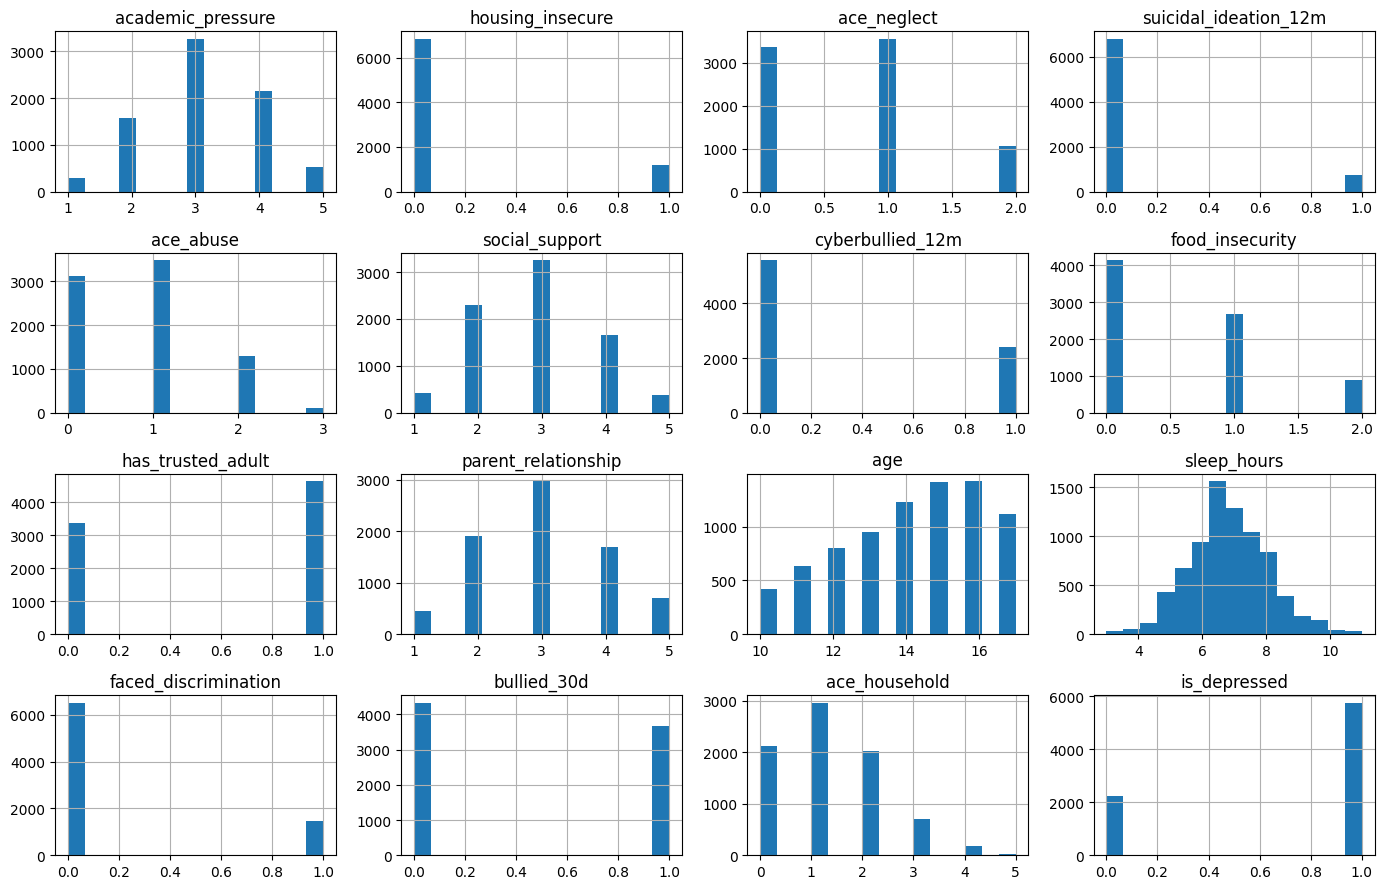

In [ ]:
df.hist(figsize=(14,9),bins=15)
plt.tight_layout()
plt.show()

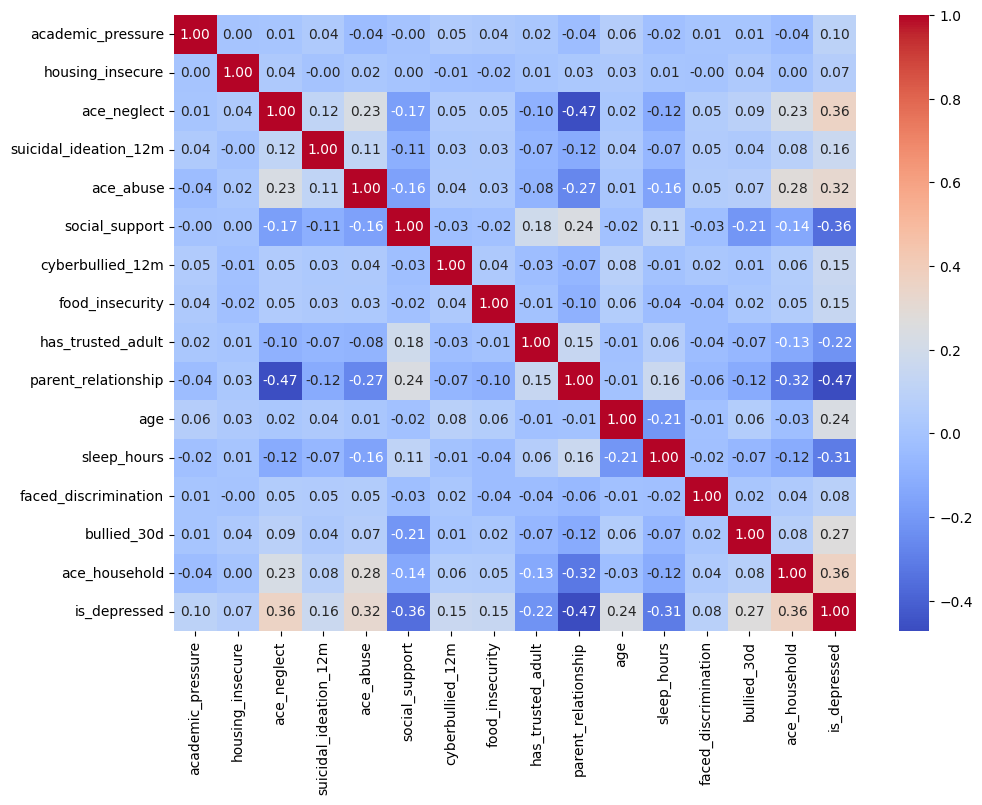

In [ ]:
plt.figure(figsize=(11,8))
sns.heatmap(df.corr(numeric_only=True),cmap='coolwarm',annot=True,fmt='.2f')
plt.show()

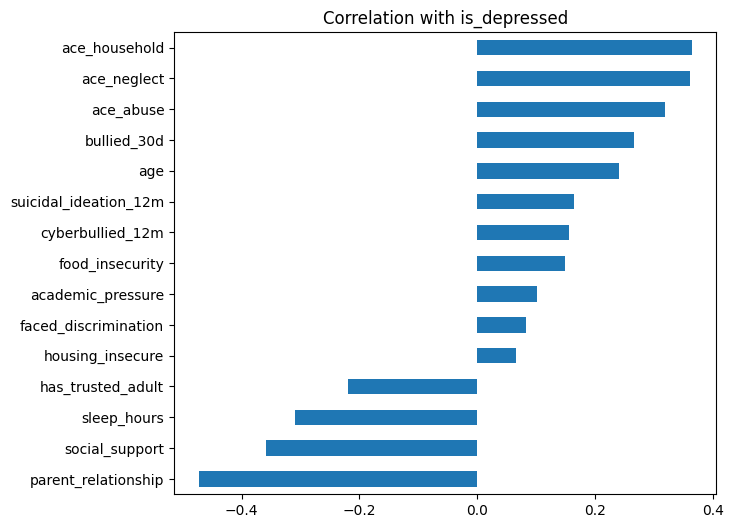

In [ ]:
df.corr(numeric_only=True)['is_depressed'].drop('is_depressed').sort_values().plot(kind='barh',figsize=(7,6))
plt.title('Correlation with is_depressed')
plt.show()

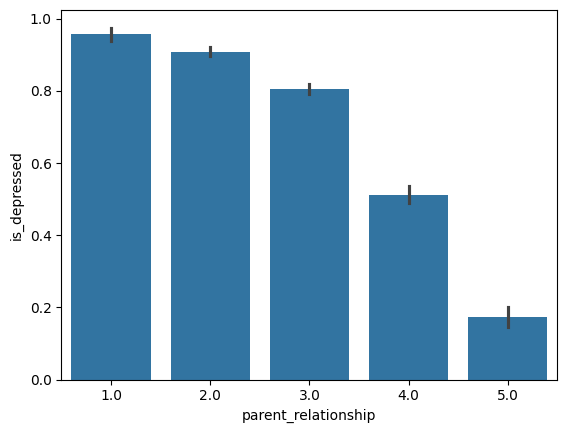

In [ ]:
sns.barplot(x='parent_relationship',y='is_depressed',data=df)
plt.show()

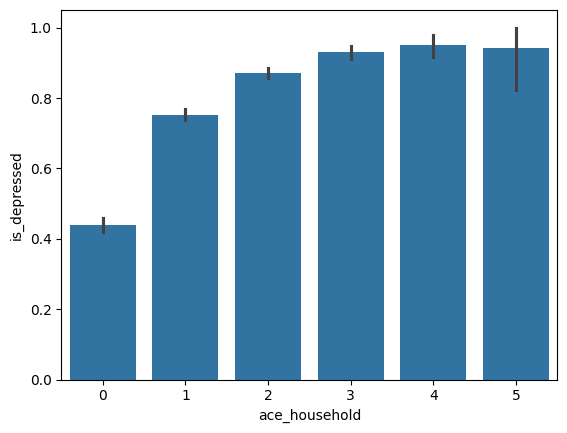

In [ ]:
sns.barplot(x='ace_household',y='is_depressed',data=df)
plt.show()

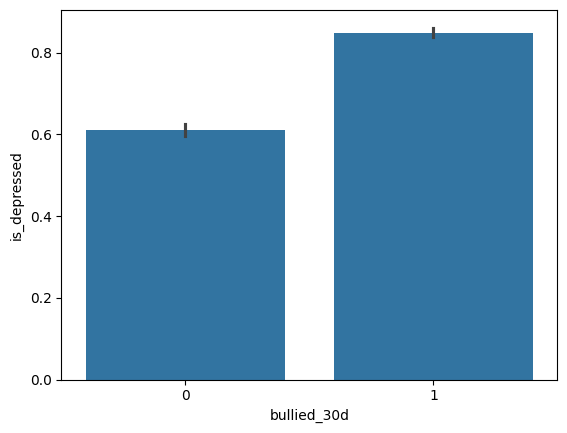

In [ ]:
sns.barplot(x='bullied_30d',y='is_depressed',data=df)
plt.show()

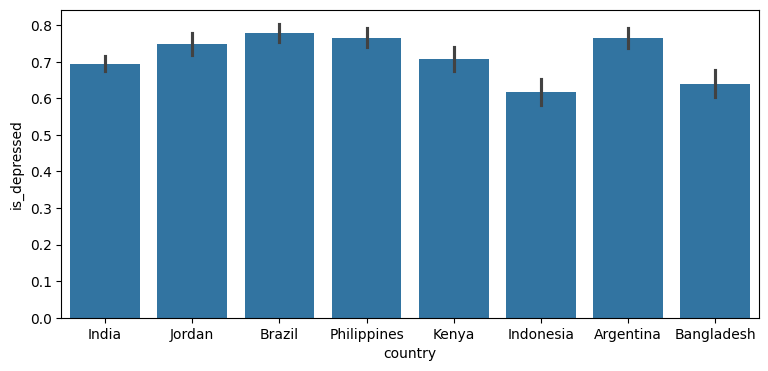

In [ ]:
plt.figure(figsize=(9,4))
sns.barplot(x='country',y='is_depressed',data=df)
plt.show()

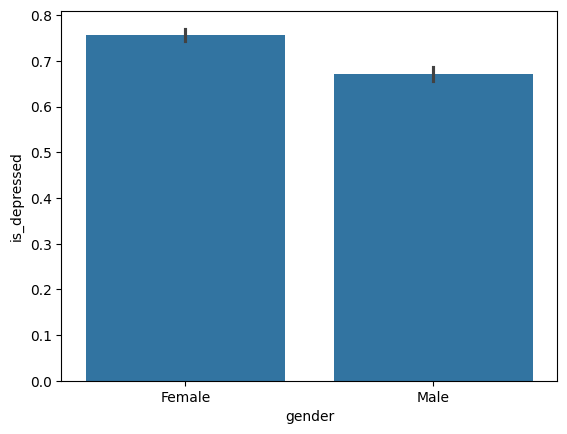

In [ ]:
sns.barplot(x='gender',y='is_depressed',data=df)
plt.show()

In [ ]:
from sklearn.model_selection import train_test_split
X=df.drop(columns='is_depressed')
y=df['is_depressed']
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.2,stratify=y,random_state=42)
print(X_train.shape,X_test.shape)

(6400, 18) (1600, 18)


In [ ]:
from sklearn.preprocessing import StandardScaler

X_train_p=X_train.copy()
X_test_p=X_test.copy()

for i in ['academic_pressure','parent_relationship','food_insecurity','sleep_hours']:
    m=X_train_p[i].median()
    X_train_p[i]=X_train_p[i].fillna(m)
    X_test_p[i]=X_test_p[i].fillna(m)

mode=X_train_p['income_level'].mode()[0]
X_train_p['income_level']=X_train_p['income_level'].fillna(mode)
X_test_p['income_level']=X_test_p['income_level'].fillna(mode)

for d in (X_train_p,X_test_p):
    d['suicidal_missing']=d['suicidal_ideation_12m'].isna().astype(int)
    d['suicidal_ideation_12m']=d['suicidal_ideation_12m'].fillna(0)
    d['gender']=d['gender'].map({'Female':0,'Male':1})
    d['income_level']=d['income_level'].map({'Low':0,'Middle':1,'High':2})

X_train_p=pd.get_dummies(X_train_p,columns=['country'],dtype=int)
X_test_p=pd.get_dummies(X_test_p,columns=['country'],dtype=int)
X_test_p=X_test_p.reindex(columns=X_train_p.columns,fill_value=0)

cols=['age','sleep_hours','academic_pressure','social_support','parent_relationship',
      'food_insecurity','income_level','ace_neglect','ace_abuse','ace_household']
sc=StandardScaler()
X_train_p[cols]=sc.fit_transform(X_train_p[cols])
X_test_p[cols]=sc.transform(X_test_p[cols])

print(X_train_p.isna().sum().sum(),X_test_p.isna().sum().sum())
print(X_train_p.shape)

0 0
(6400, 26)


In [ ]:
from sklearn.neighbors import KNeighborsClassifier
knn=KNeighborsClassifier(n_neighbors=7)
knn.fit(X_train_p,y_train)

KNeighborsClassifier(n_neighbors=7)

In [ ]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score

pred = knn.predict(X_test_p)
proba = knn.predict_proba(X_test_p)[:, 1]
print('Train accuracy:',accuracy_score(y_train,knn.predict(X_train_p)))
print('Test accuracy :',accuracy_score(y_test,pred))
print('Precision     :',precision_score(y_test,pred))
print('Recall        :',recall_score(y_test,pred))
print('F1            :',f1_score(y_test,pred))
print('ROC-AUC       :',roc_auc_score(y_test,proba))

Train accuracy: 0.916875
Test accuracy : 0.89125
Precision     : 0.8862559241706162
Recall        : 0.9739583333333334
F1            : 0.9280397022332506
ROC-AUC       : 0.9228079659598213


In [ ]:
from sklearn.metrics import classification_report
print(classification_report(y_test, pred))

              precision    recall  f1-score   support

           0       0.91      0.68      0.78       448
           1       0.89      0.97      0.93      1152

    accuracy                           0.89      1600
   macro avg       0.90      0.83      0.85      1600
weighted avg       0.89      0.89      0.89      1600



In [ ]:
from imblearn.over_sampling import SMOTE
sm=SMOTE(random_state=42)
X_train_sm,y_train_sm=sm.fit_resample(X_train_p,y_train)
print(y_train.value_counts())
print(y_train_sm.value_counts())

is_depressed
1    4608
0    1792
Name: count, dtype: int64
is_depressed
1    4608
0    4608
Name: count, dtype: int64


In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score,precision_score,recall_score,f1_score,roc_auc_score,classification_report,confusion_matrix
model=LogisticRegression(max_iter=1000)
model.fit(X_train_p,y_train)
pred=model.predict(X_test_p)
proba=model.predict_proba(X_test_p)[:,1]

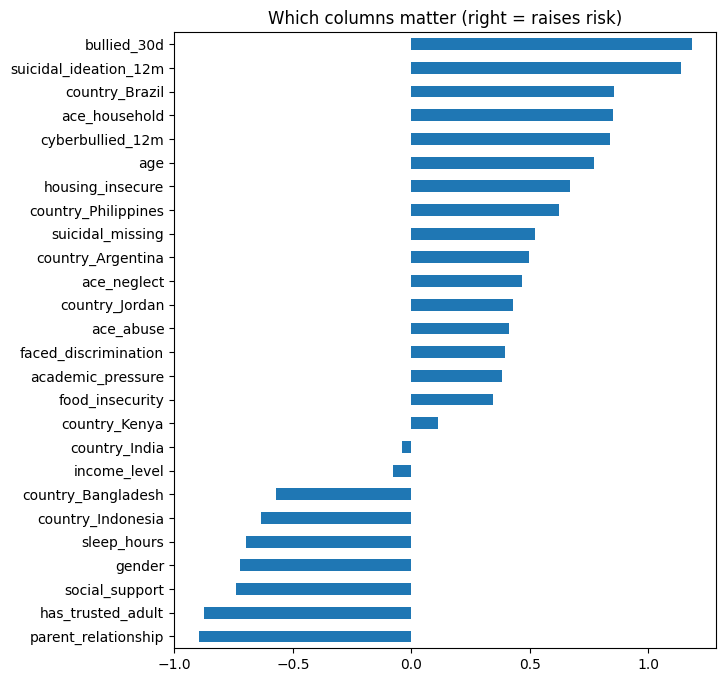

In [ ]:
pd.Series(model.coef_[0],index=X_train_p.columns).sort_values().plot(kind='barh',figsize=(7,8))
plt.title('Which columns matter (right = raises risk)')
plt.show()

              precision    recall  f1-score   support

           0       0.75      0.83      0.79       448
           1       0.93      0.89      0.91      1152

    accuracy                           0.87      1600
   macro avg       0.84      0.86      0.85      1600
weighted avg       0.88      0.87      0.88      1600



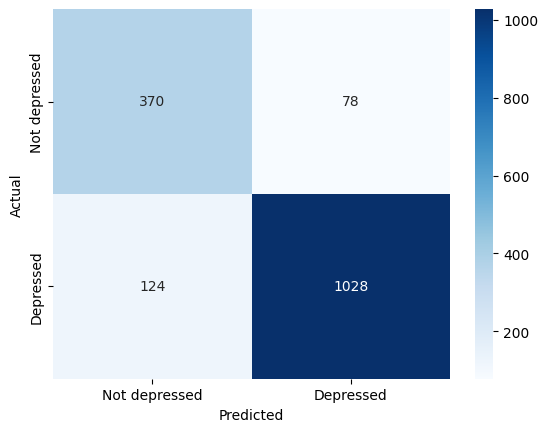

In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix, classification_report
import seaborn as sns
import matplotlib.pyplot as plt

model_sm = LogisticRegression(max_iter=1000)
model_sm.fit(X_train_sm, y_train_sm)

pred_sm = model_sm.predict(X_test_p)

print(classification_report(y_test, pred_sm))

cm = confusion_matrix(y_test, pred_sm)

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Not depressed', 'Depressed'],
    yticklabels=['Not depressed', 'Depressed']
)

plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()

In [ ]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    confusion_matrix
)

# Train Random Forest on SMOTE data
rf = RandomForestClassifier(
    n_estimators=200,
    max_depth=10,
    random_state=42,
    class_weight='balanced'
)

rf.fit(X_train_sm, y_train_sm)

# Predictions
rf_pred = rf.predict(X_test_p)
rf_proba = rf.predict_proba(X_test_p)[:,1]

# Metrics
print("Accuracy :", accuracy_score(y_test, rf_pred))
print("Precision:", precision_score(y_test, rf_pred))
print("Recall   :", recall_score(y_test, rf_pred))
print("F1 Score :", f1_score(y_test, rf_pred))
print("ROC AUC  :", roc_auc_score(y_test, rf_proba))

print("\nClassification Report")
print(classification_report(y_test, rf_pred))

Accuracy : 0.905
Precision: 0.9222972972972973
Recall   : 0.9479166666666666
F1 Score : 0.934931506849315
ROC AUC  : 0.946044921875

Classification Report
              precision    recall  f1-score   support

           0       0.86      0.79      0.82       448
           1       0.92      0.95      0.93      1152

    accuracy                           0.91      1600
   macro avg       0.89      0.87      0.88      1600
weighted avg       0.90      0.91      0.90      1600



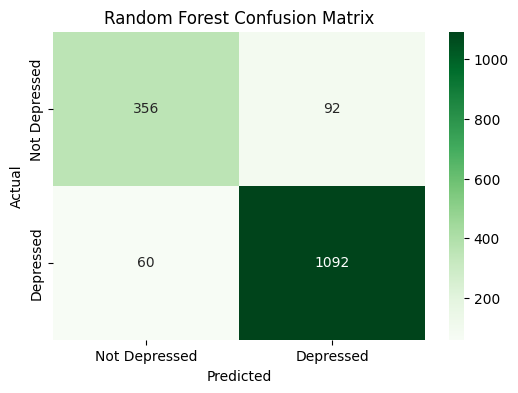

In [ ]:
cm = confusion_matrix(y_test, rf_pred)

plt.figure(figsize=(6,4))
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Greens',
    xticklabels=['Not Depressed','Depressed'],
    yticklabels=['Not Depressed','Depressed']
)

plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Random Forest Confusion Matrix')
plt.show()

In [ ]:
lr_pred = model.predict(X_test_p)
lr_proba = model.predict_proba(X_test_p)[:, 1]

comparison = pd.DataFrame({
    'Model': ['Logistic Regression', 'Random Forest'],
    'Accuracy': [accuracy_score(y_test, lr_pred), accuracy_score(y_test, rf_pred)],
    'Precision': [precision_score(y_test, lr_pred), precision_score(y_test, rf_pred)],
    'Recall': [recall_score(y_test, lr_pred), recall_score(y_test, rf_pred)],
    'F1': [f1_score(y_test, lr_pred), f1_score(y_test, rf_pred)],
    'ROC_AUC': [roc_auc_score(y_test, lr_proba), roc_auc_score(y_test, rf_proba)]
})
comparison


,Model,Accuracy,Precision,Recall,F1,ROC_AUC
0,Logistic Regression,0.890,0.915673,0.933160,0.924334,0.933824
1,Random Forest,0.905,0.922297,0.947917,0.934932,0.946045


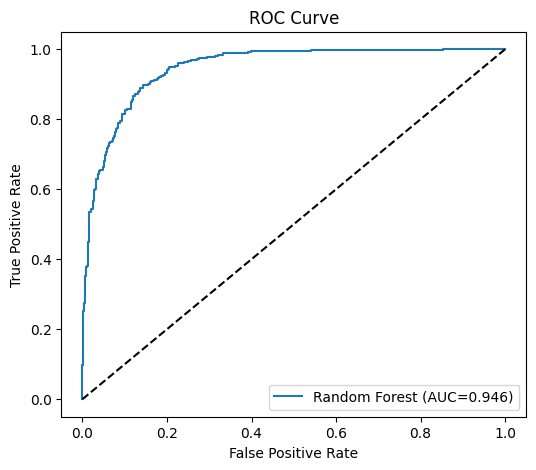

In [ ]:
from sklearn.metrics import roc_curve

fpr, tpr, _ = roc_curve(y_test, rf_proba)

plt.figure(figsize=(6,5))
plt.plot(fpr, tpr, label=f'Random Forest (AUC={roc_auc_score(y_test,rf_proba):.3f})')
plt.plot([0,1],[0,1],'k--')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve')
plt.legend()
plt.show()

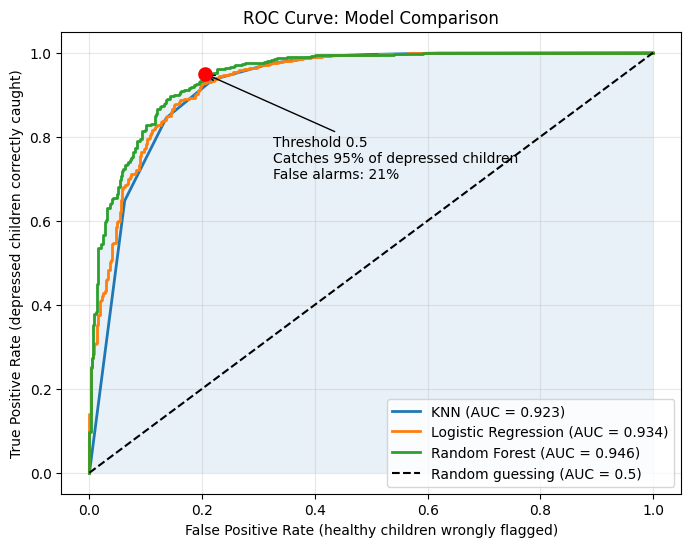

,Threshold,Depressed caught (TPR),False alarms (FPR)
0,0.3,0.995,0.411
1,0.5,0.948,0.205
2,0.7,0.798,0.094


In [ ]:
from sklearn.metrics import roc_curve, roc_auc_score, confusion_matrix
import numpy as np

knn_proba = knn.predict_proba(X_test_p)[:, 1]
models = {'KNN': knn_proba, 'Logistic Regression': lr_proba, 'Random Forest': rf_proba}

plt.figure(figsize=(8, 6))
for name, p in models.items():
    fpr, tpr, thr = roc_curve(y_test, p)
    plt.plot(fpr, tpr, lw=2, label=f'{name} (AUC = {roc_auc_score(y_test, p):.3f})')

# shade the area under the Random Forest curve
fpr, tpr, thr = roc_curve(y_test, rf_proba)
plt.fill_between(fpr, tpr, alpha=0.1)

# random guessing line
plt.plot([0, 1], [0, 1], 'k--', label='Random guessing (AUC = 0.5)')

# mark the normal 0.5 threshold on Random Forest
i = np.argmin(np.abs(thr - 0.5))
plt.scatter(fpr[i], tpr[i], s=90, color='red', zorder=5)
plt.annotate(f'Threshold 0.5\nCatches {tpr[i]*100:.0f}% of depressed children\nFalse alarms: {fpr[i]*100:.0f}%',
             (fpr[i], tpr[i]), xytext=(fpr[i] + 0.12, tpr[i] - 0.25),
             arrowprops=dict(arrowstyle='->'))

plt.xlabel('False Positive Rate (healthy children wrongly flagged)')
plt.ylabel('True Positive Rate (depressed children correctly caught)')
plt.title('ROC Curve: Model Comparison')
plt.legend(loc='lower right')
plt.grid(alpha=0.3)
plt.show()

# what changing the threshold does (Random Forest)
rows = []
for t in [0.3, 0.5, 0.7]:
    tn, fp, fn, tp = confusion_matrix(y_test, (rf_proba >= t).astype(int)).ravel()
    rows.append({'Threshold': t,
                 'Depressed caught (TPR)': tp / (tp + fn),
                 'False alarms (FPR)': fp / (fp + tn)})
pd.DataFrame(rows).round(3)

In [ ]:
import pickle
pickle.dump(rf, open('rf_depression_model.sav', 'wb'))
pickle.dump(sc, open('scaler_depression.sav', 'wb'))